# statics replay

##  验证分布函数的中心极限

In [2]:
import numpy as np

import seaborn as sns

import matplotlib.pyplot  as plt

from scipy.stats import kstest, norm




In [5]:
def generate_clt_sample(sample_size_n, trial_count ):
    '''
    sample_size_n: 每组随机变量的样本量
    trial_count  : 重复次数
    exp(laumda = 1), mu = 1 , sigma**2 = 1
    z = sqrt(n) *(x - mu )  z~(0,1)
    '''
    z_list = []
    mu = 1
    for _ in range(trial_count):
        raw = np.random.exponential(scale = 1 , size = trial_count)
        x_bar = np.mean(raw)
        z = np.sqrt(sample_size_n) *(x_bar - mu)
        z_list.append(z)
    return np.array(z_list)


    

n =   5|KS 统计量 = 0.4557|p-value = 0.0000
n =  20|KS 统计量 = 0.4164|p-value = 0.0000
n =  80|KS 统计量 = 0.3514|p-value = 0.0000
n = 250|KS 统计量 = 0.2697|p-value = 0.0000


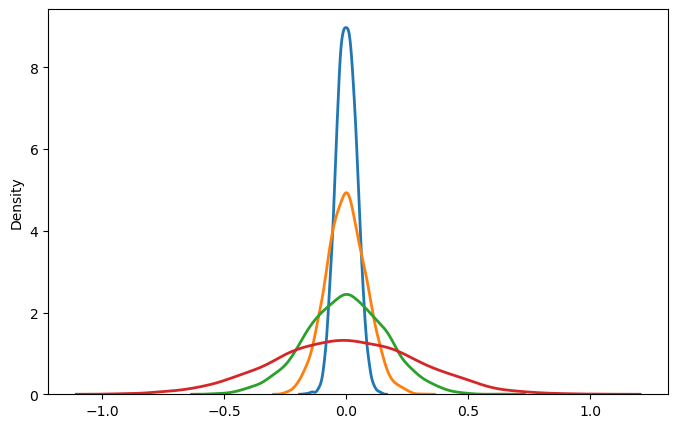

In [10]:
np.random.seed(100)
n_seq = [5, 20, 80, 250]
plt.figure(figsize = (8,5))
for n in n_seq :
    z_data = generate_clt_sample(sample_size_n=n, trial_count = 3000)
    sns.kdeplot(z_data, label = f"n = {n}", linewidth = 2)
    stat, p_val = kstest(z_data, "norm")
    print(f"n = {n:3d}|KS 统计量 = {stat:.4f}|p-value = {p_val:.4f}")



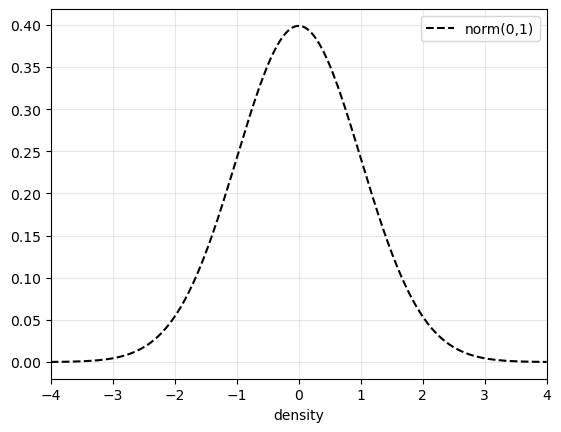

In [18]:
x_axis = np.linspace(-4, 4, 200)
y_norm = norm.pdf(x_axis, loc=0 , scale = 1) 
plt.plot(x_axis, y_norm, "k--", label = "norm(0,1)")
plt.xlim([-4, 4])
plt.xlabel("z")
plt.xlabel("density")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

